In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Locate the project data folder
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "rossmann_modeling.csv"

# Load the prepared dataset
df = pd.read_csv(data_path, parse_dates=["Date"])

# Sort records chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("BizInsight - Week 9 ML Experiments")
print("----------------------------------")
print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())


BizInsight - Week 9 ML Experiments
----------------------------------
Dataset shape: (844338, 23)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_53751/3894407689.py:19: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path, parse_dates=["Date"])


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistanceMissing,Year,Month,Day,WeekOfYear
0,85,2,2013-01-01,4220,619,1,0,a,1,b,...,2011.0,0,NaN,NaN,NaN,0,2013,1,1,1
1,1097,2,2013-01-01,5961,1405,1,0,a,1,b,...,2002.0,0,NaN,NaN,NaN,0,2013,1,1,1
2,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1
3,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1999.0,0,NaN,NaN,NaN,0,2013,1,1,1
4,682,2,2013-01-01,3375,566,1,0,a,1,b,...,2006.0,0,NaN,NaN,NaN,0,2013,1,1,1


In [2]:
# Use the same chronological split as Week 8
train_data = df[df["Date"] < "2015-05-01"].copy()

validation_data = df[
    (df["Date"] >= "2015-05-01") &
    (df["Date"] < "2015-06-01")
].copy()

# Calculate average sales per store and weekday
baseline = (
    train_data
    .groupby(["Store", "DayOfWeek"])["Sales"]
    .mean()
)

# Generate predictions for validation data
baseline_predictions = pd.Series(
    validation_data.set_index(
        ["Store", "DayOfWeek"]
    ).index.map(baseline),
    index=validation_data.index
)

# Fallback for combinations not seen in training
baseline_predictions = baseline_predictions.fillna(
    train_data["Sales"].mean()
)

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    validation_data["Sales"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        validation_data["Sales"],
        baseline_predictions
    )
)

print("Baseline Model - Validation Evaluation")
print("--------------------------------------")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")

# Display sample predictions
baseline_results = validation_data[
    ["Date", "Store", "Sales"]
].copy()

baseline_results["PredictedSales"] = (
    baseline_predictions.round(2)
)

display(baseline_results.head(10))


Baseline Model - Validation Evaluation
--------------------------------------
MAE: 1016.53
RMSE: 1359.94


,Date,Store,Sales,PredictedSales
759848,2015-05-01,512,10534,6049.68
759849,2015-05-01,562,22866,18742.40
759850,2015-05-01,676,16555,7574.19
759851,2015-05-01,682,8406,12135.36
759852,2015-05-01,948,13571,7082.78
759853,2015-05-01,769,15302,11769.29
759854,2015-05-01,1097,17039,9892.74
759855,2015-05-01,1081,4374,6245.34
759856,2015-05-01,733,19899,15950.83
759857,2015-05-01,494,8347,7832.17


In [3]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Week 9 - Step 3: Decision Tree Model

# Select features
features = [
    "Store", "DayOfWeek", "Month", "Day",
    "Promo", "SchoolHoliday", "StoreType"
]

# Prepare training and validation features
X_train = pd.get_dummies(
    train_data[features],
    columns=["StoreType"],
    dtype=int
)

X_val = pd.get_dummies(
    validation_data[features],
    columns=["StoreType"],
    dtype=int
)

# Ensure identical feature columns
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train_data["Sales"]
y_val = validation_data["Sales"]

# Create and train the model
decision_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

decision_tree.fit(X_train, y_train)

# Predict validation sales
tree_predictions = decision_tree.predict(X_val)

# Evaluate model
tree_mae = mean_absolute_error(
    y_val, tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(y_val, tree_predictions)
)

print("Decision Tree - Validation Evaluation")
print("-------------------------------------")
print(f"MAE: {tree_mae:.2f}")
print(f"RMSE: {tree_rmse:.2f}")

# Compare with baseline
print("\nBaseline vs Decision Tree")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Decision Tree MAE: {tree_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Decision Tree RMSE: {tree_rmse:.2f}")

Decision Tree - Validation Evaluation
-------------------------------------
MAE: 1982.81
RMSE: 2747.39

Baseline vs Decision Tree
Baseline MAE: 1016.53
Decision Tree MAE: 1982.81
Baseline RMSE: 1359.94
Decision Tree RMSE: 2747.39


In [4]:
from sklearn.ensemble import RandomForestRegressor

# Week 9 - Step 4: Random Forest Model

# Create Random Forest model
random_forest = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest.fit(X_train, y_train)

# Predict validation sales
rf_predictions = random_forest.predict(X_val)

# Evaluate predictions
rf_mae = mean_absolute_error(
    y_val, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

print("Random Forest - Validation Evaluation")
print("-------------------------------------")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")

# Compare all three models
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        tree_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        tree_rmse,
        rf_rmse
    ]
})

comparison = comparison.sort_values("MAE")

print("\nModel Comparison:")
display(comparison.round(2))


Random Forest - Validation Evaluation
-------------------------------------
MAE: 1875.29
RMSE: 2594.89

Model Comparison:


,Model,MAE,RMSE
0,Baseline,1016.53,1359.94
2,Random Forest,1875.29,2594.89
1,Decision Tree,1982.81,2747.39


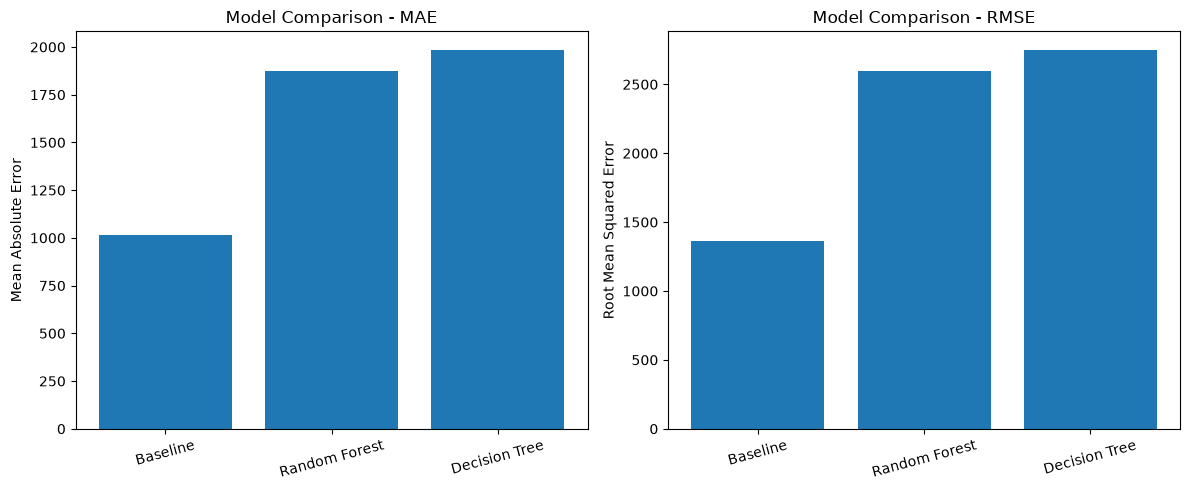

Best Model Based on Validation MAE
----------------------------------
Model: Baseline
MAE: 1016.53
RMSE: 1359.94


In [5]:
import matplotlib.pyplot as plt

# Week 9 - Step 5: Model Comparison

# Sort models by MAE
comparison = comparison.sort_values("MAE")

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MAE comparison
axes[0].bar(
    comparison["Model"],
    comparison["MAE"]
)
axes[0].set_title("Model Comparison - MAE")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=15)

# RMSE comparison
axes[1].bar(
    comparison["Model"],
    comparison["RMSE"]
)
axes[1].set_title("Model Comparison - RMSE")
axes[1].set_ylabel("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Identify best-performing model
best_model = comparison.iloc[0]

print("Best Model Based on Validation MAE")
print("----------------------------------")
print("Model:", best_model["Model"])
print(f"MAE: {best_model['MAE']:.2f}")
print(f"RMSE: {best_model['RMSE']:.2f}")


In [6]:
from pathlib import Path

# Create results directory
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison.to_csv(
    results_dir / "week9_model_comparison.csv",
    index=False
)

# Identify best model
best_model = comparison.iloc[0]

# Calculate Random Forest improvement over Decision Tree
improvement = (
    (tree_mae - rf_mae) / tree_mae
) * 100

print("BizInsight - Week 9 Final Summary")
print("---------------------------------")
print("Models evaluated: 3")
print("Evaluation period: May 2015")
print("Evaluation metrics: MAE and RMSE")

print("\nBest-performing model:")
print(f"Model: {best_model['Model']}")
print(f"MAE: {best_model['MAE']:.2f}")
print(f"RMSE: {best_model['RMSE']:.2f}")

print("\nMachine Learning Results:")
print(f"Decision Tree MAE: {tree_mae:.2f}")
print(f"Random Forest MAE: {rf_mae:.2f}")
print(
    f"Random Forest improves on Decision Tree "
    f"by {improvement:.2f}% in MAE."
)

print("\nConclusion:")
print(
    "The baseline achieved the lowest validation error. "
    "Random Forest outperformed Decision Tree, but neither "
    "ML model surpassed the baseline. Further feature "
    "engineering and model tuning may improve performance."
)

print("\nResults saved to:")
print(results_dir / "week9_model_comparison.csv")


BizInsight - Week 9 Final Summary
---------------------------------
Models evaluated: 3
Evaluation period: May 2015
Evaluation metrics: MAE and RMSE

Best-performing model:
Model: Baseline
MAE: 1016.53
RMSE: 1359.94

Machine Learning Results:
Decision Tree MAE: 1982.81
Random Forest MAE: 1875.29
Random Forest improves on Decision Tree by 5.42% in MAE.

Conclusion:
The baseline achieved the lowest validation error. Random Forest outperformed Decision Tree, but neither ML model surpassed the baseline. Further feature engineering and model tuning may improve performance.

Results saved to:
/Users/martinagj/Desktop/BizInsight/bizinsight/results/week9_model_comparison.csv
